# Connection Collective: Event Analysis
Fall 2023 – Fall 2026 event log (78 rows). This notebook cleans the data, then looks at attendance, capacity, timing, format, and the reasons Leads gave for high/low turnout.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70)

raw = pd.read_excel('/mnt/project/connection_collective_event_data.xlsx', sheet_name='Sheet2')
print(raw.shape)
raw.head(3)

(78, 28)


,Event_Name,Semester,Year,Number_Attendees,Limit,Time,Type_event,Capped_YN,Food_YN,Waitlist,...,Program,Series,Partner_or_Guest,Expenses_Total,Expenses_Details,Attendance_Factors,Repeat_Recommendation,Reflection_Summary,Notes,Source
0,Connection Collective October Social - cookie-decorating and stres...,Fall,2023,15.0,20.0,evening,creative,Yes,Yes,No,...,Connection Collective,Social,NaN,NaN,NaN,NaN,NaN,NaN,Planned/hosted by upper-year Connection Leads for first-year stude...,Event sheet (Fall 2023-Winter 2026)
1,Connection Collective: Collective Chill - mini-pumpkin painting night,Fall,2023,4.0,10.0,evening,creative,Yes,No,No,...,Connection Collective,Collective Chill,NaN,NaN,NaN,NaN,NaN,NaN,"First ""Collective Chill"". Hosted by Connection Leads Courtni and E...",Event sheet (Fall 2023-Winter 2026)
2,Connection Collective November Social - gingerbread cookie-decorat...,Fall,2023,5.0,10.0,evening,creative,Yes,Yes,No,...,Connection Collective,Social,NaN,NaN,NaN,NaN,NaN,NaN,Second CC social event. Gingerbread cookie decorating + tote bag p...,Event sheet (Fall 2023-Winter 2026)


## 1. Cleaning & scoping
Two rows aren't comparable to the rest, so I split them out:
- **Orientation Leader Training** (550 attendees, an estimate) and the other non-CC *Community Leadership Certificate* rows are not Connection Collective events.
- Rows with **no recorded attendance** (7) can't be used in attendance stats.

A fresh column `Term` orders semesters chronologically (Spring 2024 = the summer pre-arrival run).

In [2]:
df = raw.copy()
df['Fill_Rate'] = df['Number_Attendees'] / df['Limit']
df['Month'] = df['Date'].dt.to_period('M')
order = {'Fall':3,'Winter':1,'Spring':2}   # Winter(Jan-Apr) < Spring(May-Aug) < Fall(Sep-Dec)
df['Term'] = df['Semester'] + ' ' + df['Year'].astype(str)
df['TermKey'] = df['Year']*10 + df['Semester'].map(order)

cc = df[(df['Program']=='Connection Collective')].copy()
att = cc[cc['Number_Attendees'].notna()].copy()

print(f"All rows: {len(df)} | Connection Collective events: {len(cc)} | with attendance recorded: {len(att)}")
print(f"Excluded as non-CC: {(df['Program']!='Connection Collective').sum()}")
print(f"Missing attendance among CC: {cc['Number_Attendees'].isna().sum()}")
print(f"Date range: {df['Date'].min().date()} → {df['Date'].max().date()}")

All rows: 78 | Connection Collective events: 75 | with attendance recorded: 68
Excluded as non-CC: 3
Missing attendance among CC: 7
Date range: 2023-10-19 → 2026-10-14


## 2. Headline numbers

In [3]:
s = att['Number_Attendees']
summary = pd.Series({
    'Events with attendance': len(att),
    'Total attendances': int(s.sum()),
    'Mean per event': round(s.mean(),1),
    'Median per event': s.median(),
    'Max single event': int(s.max()),
    'Events with ≤5 attendees': int((s<=5).sum()),
    'Share with ≤5 attendees': f"{(s<=5).mean():.0%}",
    'Events at/over capacity': int((att['Fill_Rate']>=1).sum()),
})
summary.to_frame('value')

,value
Events with attendance,68
Total attendances,767
Mean per event,11.3
Median per event,8.0
Max single event,55
Events with ≤5 attendees,23
Share with ≤5 attendees,34%
Events at/over capacity,3


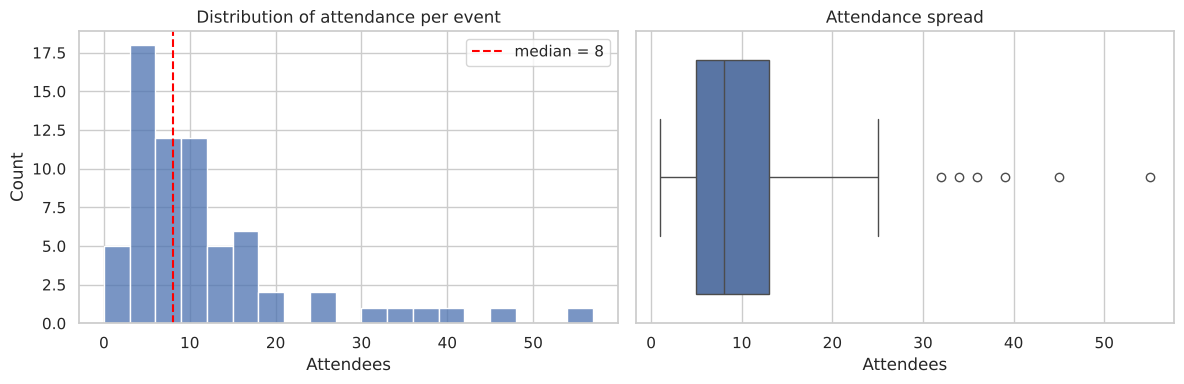

In [4]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(s, bins=range(0,60,3), ax=ax[0], color='#4C72B0')
ax[0].axvline(s.median(), color='red', ls='--', label=f'median = {s.median():.0f}')
ax[0].set(title='Distribution of attendance per event', xlabel='Attendees'); ax[0].legend()
sns.boxplot(x=s, ax=ax[1], color='#4C72B0'); ax[1].set(title='Attendance spread', xlabel='Attendees')
plt.tight_layout(); plt.show()

The mean is pulled up by a handful of big events; the **median is the better 'typical event' figure**.

## 3. Attendance over time

,Term,events,total,mean,median
0,Fall 2023,3,24.0,8.0,5.0
1,Winter 2024,9,94.0,10.4,12.0
2,Spring 2024,8,208.0,26.0,20.0
3,Fall 2024,9,72.0,8.0,6.0
4,Winter 2025,6,33.0,5.5,5.5
5,Spring 2025,2,12.0,6.0,6.0
6,Fall 2025,5,99.0,19.8,13.0
7,Winter 2026,5,77.0,15.4,9.0
8,Spring 2026,14,91.0,6.5,5.5
9,Fall 2026,7,57.0,8.1,8.0


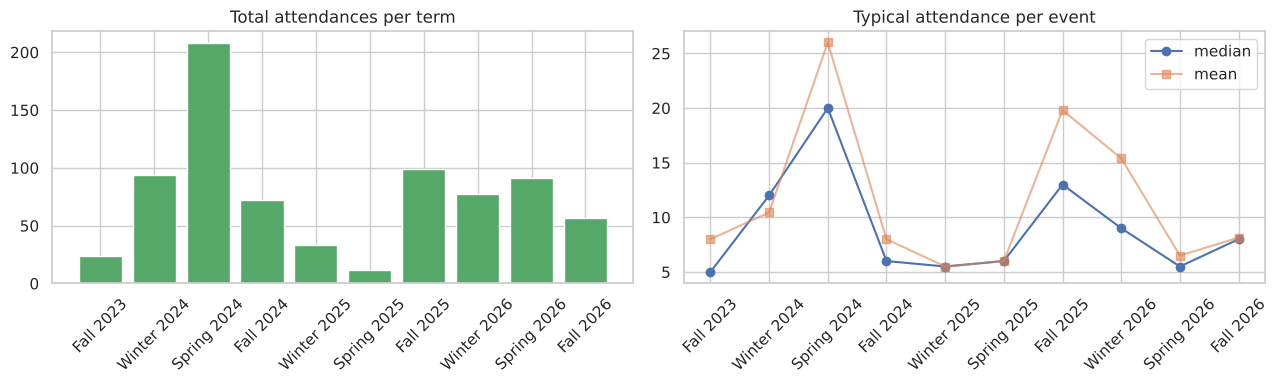

In [5]:
term = (att.groupby(['TermKey','Term'])['Number_Attendees']
        .agg(events='count', total='sum', mean='mean', median='median').reset_index().sort_values('TermKey'))
display(term.drop(columns='TermKey').round(1))

fig, ax = plt.subplots(1,2, figsize=(13,4))
ax[0].bar(term['Term'], term['total'], color='#55A868'); ax[0].set_title('Total attendances per term')
ax[1].plot(term['Term'], term['median'], marker='o', label='median')
ax[1].plot(term['Term'], term['mean'], marker='s', label='mean', alpha=.6)
ax[1].set_title('Typical attendance per event'); ax[1].legend()
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

**Spring 2024 is an outlier** because it's the virtual *Pre-Arrival* programming for incoming students (up to 55 people). Excluding Pre-Arrival gives a fairer view of regular in-term events:

,Term,events,total,median,mean
0,Fall 2023,3,24.0,5.0,8.0
1,Winter 2024,9,94.0,12.0,10.4
2,Fall 2024,9,72.0,6.0,8.0
3,Winter 2025,6,33.0,5.5,5.5
4,Spring 2025,2,12.0,6.0,6.0
5,Fall 2025,5,99.0,13.0,19.8
6,Winter 2026,5,77.0,9.0,15.4
7,Spring 2026,14,91.0,5.5,6.5
8,Fall 2026,7,57.0,8.0,8.1


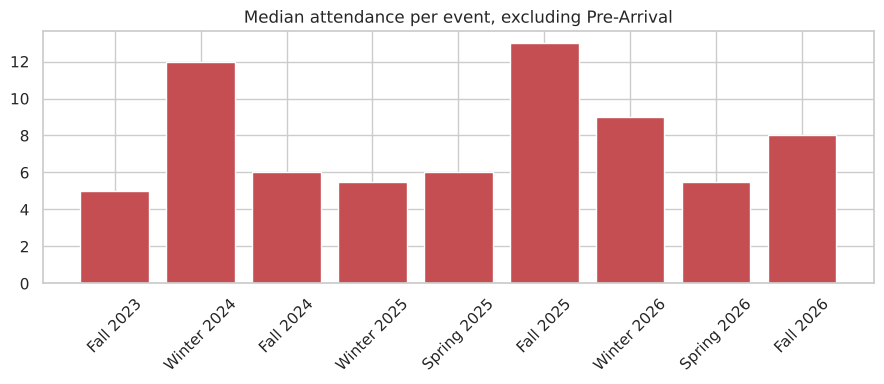

In [6]:
regular = att[att['Series']!='Pre-Arrival']
t2 = (regular.groupby(['TermKey','Term'])['Number_Attendees']
      .agg(events='count', total='sum', median='median', mean='mean').reset_index().sort_values('TermKey'))
display(t2.drop(columns='TermKey').round(1))
plt.figure(figsize=(9,4)); plt.bar(t2['Term'], t2['median'], color='#C44E52')
plt.title('Median attendance per event, excluding Pre-Arrival'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 4. What kind of event draws people?

In [7]:
def grp(col, data=att):
    return (data.groupby(col)['Number_Attendees']
            .agg(events='count', mean='mean', median='median', max='max').round(1)
            .sort_values('median', ascending=False))

print('— By Series (program branding)'); display(grp('Series'))
print('— By Event Type'); display(grp('Type_event'))

— By Series (program branding)


,events,mean,median,max
Series,,,,
Pre-Arrival,8,26.0,20.0,55.0
Social,3,11.7,15.0,15.0
Collective Chill,29,12.4,10.0,36.0
Chill Spaces,17,5.9,6.0,10.0
Conversations,8,6.5,5.5,16.0
Collaboration,2,3.5,3.5,4.0
Special Event,1,3.0,3.0,3.0


— By Event Type


,events,mean,median,max
Type_event,,,,
workshop,3,17.7,16.0,24.0
food,1,12.0,12.0,12.0
party,12,11.0,11.0,18.0
creative,21,12.2,8.0,36.0
discussion,13,15.9,8.0,55.0
drop-in,17,5.9,6.0,10.0
study,1,6.0,6.0,6.0


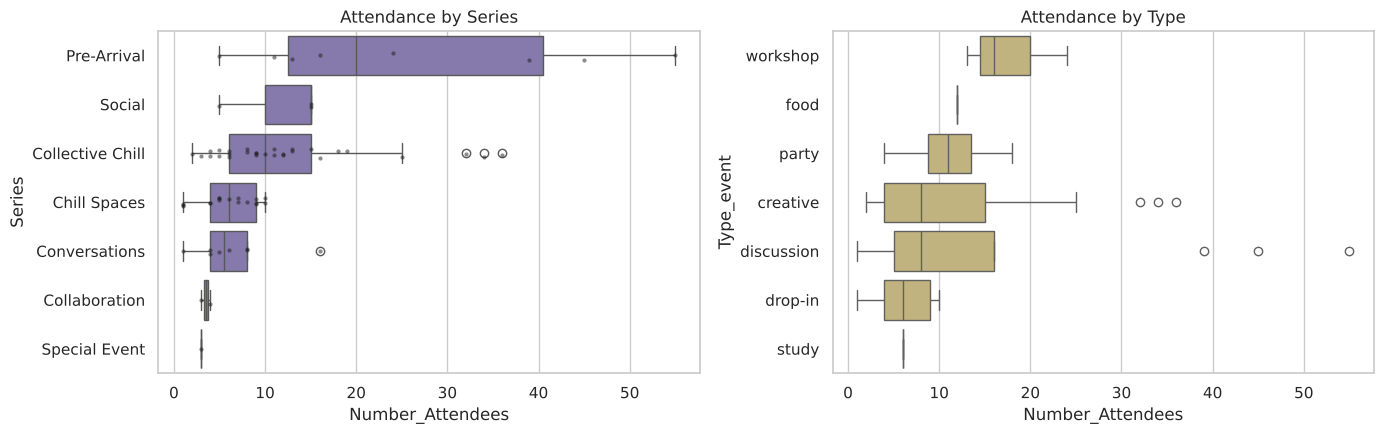

In [8]:
fig, ax = plt.subplots(1,2, figsize=(14,4.5))
sns.boxplot(data=att, y='Series', x='Number_Attendees', ax=ax[0], order=grp('Series').index, color='#8172B3')
sns.stripplot(data=att, y='Series', x='Number_Attendees', ax=ax[0], order=grp('Series').index, color='k', size=3, alpha=.5)
ax[0].set_title('Attendance by Series')
sns.boxplot(data=att, y='Type_event', x='Number_Attendees', ax=ax[1], order=grp('Type_event').index, color='#CCB974')
ax[1].set_title('Attendance by Type'); plt.tight_layout(); plt.show()

## 5. Timing: time of day, day of week

— Time of day


,events,mean,median,max
Time,,,,
morning,4,37.5,42.0,55.0
afternoon,21,14.1,12.0,36.0
evening,22,7.8,6.0,24.0


— Day of week


,events,mean,median,max
Day_of_Week,,,,
Monday,5,8.0,5.0,18.0
Tuesday,8,20.0,7.5,55.0
Wednesday,29,7.5,7.0,16.0
Thursday,18,13.8,9.5,39.0
Friday,8,12.6,12.0,24.0


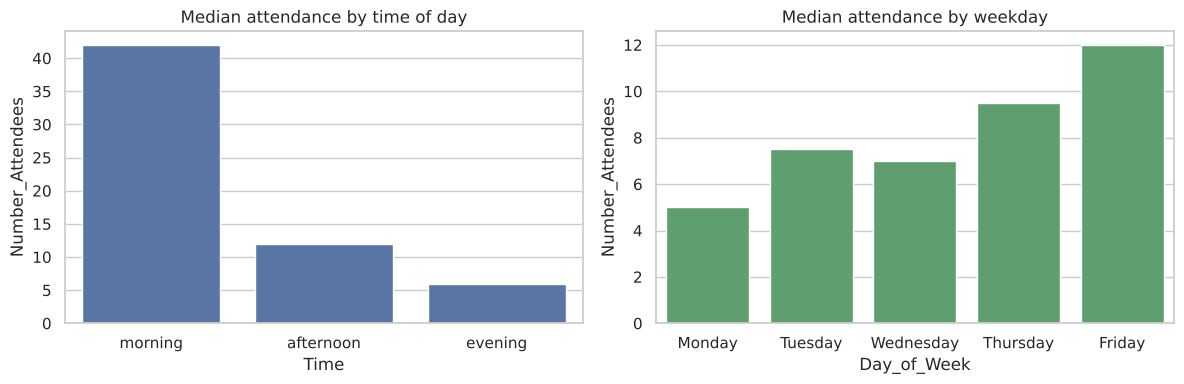

In [9]:
print('— Time of day'); display(grp('Time'))
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']
d = grp('Day_of_Week').reindex([x for x in dow_order if x in att['Day_of_Week'].values]); print('— Day of week'); display(d)

fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.barplot(data=att, x='Time', y='Number_Attendees', order=['morning','afternoon','evening'], estimator=np.median, errorbar=None, ax=ax[0], color='#4C72B0')
ax[0].set_title('Median attendance by time of day')
sns.barplot(data=att, x='Day_of_Week', y='Number_Attendees', order=d.index, estimator=np.median, errorbar=None, ax=ax[1], color='#55A868')
ax[1].set_title('Median attendance by weekday'); plt.tight_layout(); plt.show()

**Careful:** the 'morning' bucket is only 4 events and they're all virtual Pre-Arrival sessions, so that bar reflects *format and audience*, not the hour. A cleaner test is to look only at **in-person events**:

In [10]:
inp = att[(att['Modality']=='In Person') & (att['Series']!='Pre-Arrival')]
print(f'In-person, non-Pre-Arrival events: {len(inp)}')
print('— Time of day'); display(grp('Time', inp))
print('— Day of week'); display(grp('Day_of_Week', inp).reindex([x for x in dow_order if x in inp['Day_of_Week'].values]))
print('— Food vs no food'); display(grp('Food_YN', inp))

In-person, non-Pre-Arrival events: 58
— Time of day


,events,mean,median,max
Time,,,,
afternoon,18,14.3,12.0,36.0
evening,19,7.1,6.0,15.0


— Day of week


,events,mean,median,max
Day_of_Week,,,,
Monday,4,8.8,6.5,18.0
Tuesday,6,10.0,5.0,34.0
Wednesday,26,7.0,6.0,16.0
Thursday,16,12.4,8.5,36.0
Friday,6,10.7,11.0,19.0


— Food vs no food


,events,mean,median,max
Food_YN,,,,
Yes,46,10.1,8.5,36.0
No,9,5.2,5.0,8.0


## 6. Format: in-person vs virtual/hybrid, and food

In [11]:
print('— Modality (all CC events)'); display(grp('Modality'))
print('— Food (all CC events)'); display(grp('Food_YN'))
print('— Virtual rows by Series')
display(att[att['Modality']!='In Person'].groupby(['Modality','Series'])['Number_Attendees'].agg(['count','median']))

— Modality (all CC events)


,events,mean,median,max
Modality,,,,
Virtual,8,26.0,20.0,55.0
Hybrid,2,9.5,9.5,11.0
In Person,58,9.3,7.5,36.0


— Food (all CC events)


,events,mean,median,max
Food_YN,,,,
Yes,48,10.1,8.5,36.0
No,17,15.0,8.0,55.0


— Virtual rows by Series


,,count,median
Modality,Series,,
Hybrid,Collective Chill,2,9.5
Virtual,Pre-Arrival,8,20.0


## 7. Capacity and waitlists
Only events with a recorded cap can be assessed (fill rate = attended ÷ limit).

Events with a cap & attendance: 36
       Fill rate
count      36.00
mean        0.54
std         0.30
min         0.15
25%         0.29
50%         0.48
75%         0.80
max         1.00

At ≥100% of limit: 3   |  Under 50%: 18
Events with waitlist:


,Event_Name,Date,Number_Attendees,Limit
3,Collective Chill Pizza Night - pizza party with music,2024-01-19,12.0,12.0
6,Collective Chill Snack Pop-Up Drop-In,2024-03-01,12.0,12.0
8,The Power of Storytelling and Shared Experiences with The Connecti...,2024-03-28,6.0,15.0
42,The Great Gingerbread Hangout,2025-11-20,32.0,32.0


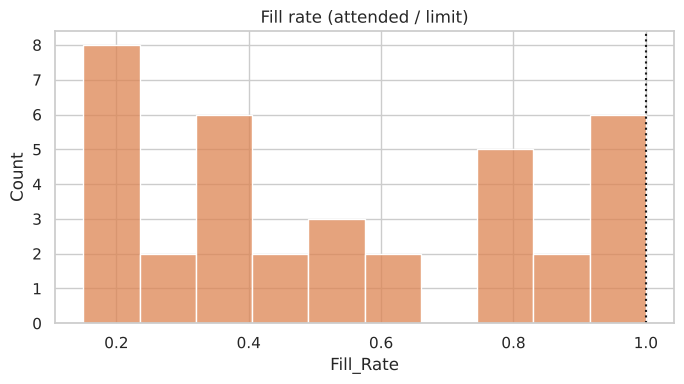

In [12]:
cap = att[att['Limit'].notna()].copy()
print(f"Events with a cap & attendance: {len(cap)}")
print(cap['Fill_Rate'].describe().round(2).to_frame('Fill rate'))
print(f"\nAt ≥100% of limit: {(cap['Fill_Rate']>=1).sum()}   |  Under 50%: {(cap['Fill_Rate']<.5).sum()}")
print('Events with waitlist:'); display(att[att['Waitlist']=='Yes'][['Event_Name','Date','Number_Attendees','Limit']])

plt.figure(figsize=(7,4)); sns.histplot(cap['Fill_Rate'], bins=10, color='#DD8452')
plt.axvline(1, color='k', ls=':'); plt.title('Fill rate (attended / limit)'); plt.tight_layout(); plt.show()

In [13]:
by_series_fill = cap.groupby('Series')['Fill_Rate'].agg(['count','mean','median']).round(2).sort_values('median')
display(by_series_fill)
print('Registered-vs-attended, lowest-filling capped events:')
display(cap.sort_values('Fill_Rate').head(8)[['Event_Name','Date','Number_Attendees','Limit','Fill_Rate','Series']].round(2))

,count,mean,median
Series,,,
Collaboration,2,0.18,0.18
Conversations,4,0.24,0.20
Special Event,1,0.20,0.20
Pre-Arrival,3,0.60,0.45
Collective Chill,23,0.60,0.62
Social,3,0.71,0.75


Registered-vs-attended, lowest-filling capped events:


/tmp/ipykernel_133/867019819.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cap.sort_values('Fill_Rate').head(8)[['Event_Name','Date','Number_Attendees','Limit','Fill_Rate','Series']].round(2))


,Event_Name,Date,Number_Attendees,Limit,Fill_Rate,Series
23,Candle-making Workshop: Connection Collective x On Empathy,2024-10-29,3.0,20.0,0.15,Collaboration
24,Equity Collective: Reflections and Connection,2024-11-18,8.0,50.0,0.16,Conversations
37,The Human Library - UWaterloo Connection Collective Edition,2025-05-22,8.0,50.0,0.16,Conversations
34,Collective Chill: Self-care Workshop,2025-03-05,2.0,12.0,0.17,Collective Chill
46,Collective Chill: Black History Month Jeopardy Night,2026-02-26,9.0,50.0,0.18,Collective Chill
11,"Palettes and Petals - As you engage in conversation, unleash your ...",2024-04-11,3.0,15.0,0.20,Special Event
38,Jeopardy-with-a-Twist,2025-07-30,4.0,20.0,0.20,Collective Chill
28,Sprout & Share: Connection Collective x On Empathy,2024-11-26,4.0,20.0,0.20,Collaboration


## 8. Best and worst events

In [14]:
cols = ['Event_Name','Date','Series','Type_event','Number_Attendees','Limit']
short = lambda d: d.assign(Event_Name=d['Event_Name'].str.slice(0,60))
print('Top 10'); display(short(regular.nlargest(10,'Number_Attendees'))[cols])
print('Bottom 10'); display(short(regular.nsmallest(10,'Number_Attendees'))[cols])

Top 10


,Event_Name,Date,Series,Type_event,Number_Attendees,Limit
48,Connection Collective: Canvas Collective,2026-04-09,Collective Chill,creative,36.0,40.0
43,Create Your Own Self-Care Bag,2025-12-02,Collective Chill,creative,34.0,NaN
42,The Great Gingerbread Hangout,2025-11-20,Collective Chill,creative,32.0,32.0
47,Collective Chill: Henna Hangout,2026-03-12,Collective Chill,creative,25.0,40.0
4,Collective Chill- Origami and Hot Chocolate Night - origami,2024-02-02,Collective Chill,creative,19.0,20.0
62,Collective Chill,2026-07-20,Collective Chill,party,18.0,NaN
20,Collective Chill: Pizza Lunch :P/ Pizza Party & Bingo Lunch,2024-09-26,Collective Chill,party,16.0,20.0
74,Conversations,2026-09-30,Conversations,discussion,16.0,NaN
0,Connection Collective October Social - cookie-decorating and,2023-10-19,Social,creative,15.0,20.0
10,Connection Collective End of Term Celebration,2024-04-03,Social,party,15.0,17.0


Bottom 10


,Event_Name,Date,Series,Type_event,Number_Attendees,Limit
33,Conversation Circle- Collective Impacts of Colonial Systems,2025-03-05,Conversations,discussion,1.0,NaN
55,Chill Spaces,2026-05-27,Chill Spaces,drop-in,1.0,NaN
67,Chill Spaces,2026-08-12,Chill Spaces,drop-in,1.0,NaN
68,Chill Spaces,2026-08-19,Chill Spaces,drop-in,1.0,NaN
34,Collective Chill: Self-care Workshop,2025-03-05,Collective Chill,creative,2.0,12.0
11,"Palettes and Petals - As you engage in conversation, unleash",2024-04-11,Special Event,creative,3.0,15.0
23,Candle-making Workshop: Connection Collective x On Empathy,2024-10-29,Collaboration,creative,3.0,20.0
45,CL Collective Chill: Self-Love Soiree,2026-02-12,Collective Chill,creative,3.0,NaN
1,Connection Collective: Collective Chill - mini-pumpkin paint,2023-10-31,Collective Chill,creative,4.0,10.0
28,Sprout & Share: Connection Collective x On Empathy,2024-11-26,Collaboration,creative,4.0,20.0


## 9. Why did turnout go up or down? (coded from Leads' own notes)
`Attendance_Factors` holds reasons the Leads stated. I tag them by keyword and compare average attendance among tagged vs untagged events.

In [15]:
fx = att.dropna(subset=['Attendance_Factors']).copy()
tags = {
  'Exam/midterm season': r'exam|midterm',
  'Weather / air quality': r'weather|snow|smoke|air quality',
  'Off-campus / hard-to-find location': r'off-campus|commute|hard to find',
  'Low promotion': r'low promotion',
  'Strong promotion / posters': r'poster run|promo at|earlier promotion|promotion on',
  'Fewer students on campus': r'fewer students|few students|few people|reading week',
  'Repeat attendees': r'repeat attendees|familiarity|consistent weekly',
}
rows=[]
for k,pat in tags.items():
    m = att['Attendance_Factors'].fillna('').str.contains(pat, case=False, regex=True)
    rows.append((k, int(m.sum()), att.loc[m,'Number_Attendees'].median(), att.loc[m,'Number_Attendees'].mean()))
tag_df = pd.DataFrame(rows, columns=['Factor','Events','Median attendees','Mean attendees']).round(1)
display(tag_df)
print(f"For reference, overall median = {att['Number_Attendees'].median()}, regular-events median = {regular['Number_Attendees'].median()}")

,Factor,Events,Median attendees,Mean attendees
0,Exam/midterm season,7,6.0,9.1
1,Weather / air quality,2,4.0,4.0
2,Off-campus / hard-to-find location,3,3.0,3.0
3,Low promotion,1,9.0,9.0
4,Strong promotion / posters,3,10.0,14.7
5,Fewer students on campus,4,2.5,2.5
6,Repeat attendees,5,9.0,8.4


For reference, overall median = 8.0, regular-events median = 8.0


In [16]:
print('Leads\' explicit repeat recommendations:')
display(cc.dropna(subset=['Repeat_Recommendation'])[['Event_Name','Number_Attendees','Repeat_Recommendation']].assign(Event_Name=lambda d: d.Event_Name.str.slice(0,55)))

Leads' explicit repeat recommendations:


,Event_Name,Number_Attendees,Repeat_Recommendation
21,Collective Chill: Group Study Session/ Midterm Study Se,6.0,No
27,Collective Chill: Board Game Night,5.0,No
34,Collective Chill: Self-care Workshop,2.0,No - not in this location
45,CL Collective Chill: Self-Love Soiree,3.0,Yes - on a larger scale
46,Collective Chill: Black History Month Jeopardy Night,9.0,No


## 10. Spending
Expense totals exist for very few events, so this is directional only.

In [17]:
ex = cc.dropna(subset=['Expenses_Total']).copy()
ex['Cost_per_attendee'] = ex['Expenses_Total']/ex['Number_Attendees']
display(ex[['Event_Name','Number_Attendees','Expenses_Total','Cost_per_attendee']].assign(Event_Name=lambda d: d.Event_Name.str.slice(0,55)).round(2))
print(f"Coverage: {len(ex)} of {len(cc)} CC events have a recorded total.")

,Event_Name,Number_Attendees,Expenses_Total,Cost_per_attendee
39,"Craft & Chill: Unwind, Create, Connect - with Ice Cream",9.0,27.62,3.07
40,Pumpkins and Popcorn,13.0,111.69,8.59
41,Gam-o-clock: Cozy Games & Good Vibes,11.0,37.99,3.45
42,The Great Gingerbread Hangout,32.0,156.96,4.90
43,Create Your Own Self-Care Bag,34.0,284.00,8.35


Coverage: 5 of 75 CC events have a recorded total.


## 11. Data-quality checklist

In [18]:
dq = pd.DataFrame({
  'Missing': cc.isna().sum(),
  'Pct': (cc.isna().mean()*100).round(0)
}).query('Missing>0').sort_values('Missing', ascending=False)
display(dq)
print('CC events with no attendance recorded:')
display(cc[cc['Number_Attendees'].isna()][['Event_Name','Term','Series']].assign(Event_Name=lambda d: d.Event_Name.str.slice(0,60)))

,Missing,Pct
Location_Region_Rule,75,100.0
Expenses_Total,70,93.0
Repeat_Recommendation,70,93.0
Partner_or_Guest,62,83.0
Expenses_Details,60,80.0
Reflection_Summary,48,64.0
Limit,39,52.0
Fill_Rate,39,52.0
Attendance_Factors,37,49.0
Waitlist,33,44.0


CC events with no attendance recorded:


,Event_Name,Term,Series
29,End-of-term Social,Fall 2024,Social
32,Black History Month Fete,Winter 2025,External Event
49,Chill Spaces - April Dates,Winter 2026,Chill Spaces
50,Chill Spaces - April Dates,Winter 2026,Chill Spaces
51,Chill Spaces - April Dates,Winter 2026,Chill Spaces
52,Chill Spaces - April Dates,Winter 2026,Chill Spaces
53,Chill Spaces - April Dates,Winter 2026,Chill Spaces
